## NAME: MALIK MUHAMMAD ALI HAIDER
## ROLL NUMBER: SP23-BBD-030
## CLASS: BBD 8A (BDS 6)
## SUBJECT: MGT389 NLP FOR BUSINESS / AIC365 NLP
## TOPIC: Lab 04-Tasks
## Submitted to: Sir Zaeem Akbar (zaeemakbar.khan@comsats.edu.pk)

In [5]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
nltk.download("stopwords"); nltk.download("movie_reviews"); nltk.download("brown")
from nltk.corpus import stopwords, movie_reviews, brown
from nltk.stem import PorterStemmer, SnowballStemmer
import spacy

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Arooba\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\Arooba\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\Arooba\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!


### **Task 01**: Lowercasing Basics and Its Drawbacks
### Understand the benefits and risks of case normalization.
### 1.	Build a small corpus of at least 10 sentences containing mixed-case words (e.g., "Apple", "apple", "APPLE", "US", "us").


In [3]:
corpus = [
    "Apple is a smartphone company.",
    "I ate an apple.",
    "APPLE iphone duo launched this year.",
    "The Iran hurt US' ego.",
    "The US attacked Iran causing a global turmoil.",
    "All of us are dead is a series I wouldn't watch.",
    "He will go to Turkey for his operation.",
    "They ate turkey for Thanksgiving .",
    "He is Polish.",
    "I need to polish my shoes.",
    "He will go to the park.",
    "Mr. Park came to meet us.",
]


#### 2.	Lowercase the corpus and compare the vocabulary size before and after.

In [4]:
tokens_before = [w for s in corpus for w in re.findall(r"[A-Za-z]+", s)]
tokens_after  = [w.lower() for w in tokens_before]
print("Vocabulary before lowercasing:", len(set(tokens_before)))
print("Vocabulary after lowercasing :", len(set(tokens_after)))

Vocabulary before lowercasing: 55
Vocabulary after lowercasing : 48


#### 3.	Find 3 examples where lowercasing makes the meaning ambiguous (e.g., "US" vs. "us", "Apple" the company vs. the fruit).

In [5]:
examples = [("US (country)", "us (pronoun)"),
            ("Apple (company)", "apple (fruit)"),
            ("Turkey (country)", "turkey (animal)")]
for a, b in examples:
    print(f"{a}  vs  {b}  ->  both become '{a.split()[0].lower()}'")

US (country)  vs  us (pronoun)  ->  both become 'us'
Apple (company)  vs  apple (fruit)  ->  both become 'apple'
Turkey (country)  vs  turkey (animal)  ->  both become 'turkey'


#### 4.	Write a short paragraph explaining which NLP tasks (NER, sentiment analysis, search) can be harmed by lowercasing, and why.


##### Lowercasing can harm Named Entity Recognition, because capital letters are a strong clue that a word is a name (Apple, US, Turkey, US); once everything is lower case the model cannot tell the company from the fruit. Sentiment analysis can lose emphasis, since ALL CAPS ("GREAT") often signals strong feeling. Search can return wrong results, for example a query for "US" matching the pronoun "us", or "Polish" matching "polish". Lowercasing helps by merging "Apple/APPLE/apple" into one word and reducing vocabulary size.

### **Task 02**: Noise Removal Pipeline
### Clean raw text using regular expressions.
#### 1.	Create or download a "noisy" dataset of tweets or reviews (at least 15 entries) containing URLs, @mentions, #hashtags, emojis, HTML tags and extra whitespace.

In [7]:
noisy = [
    "Loved the movie!!! 😍😍 http://t.co/abc123 #Awesome @john_doe",
    "<p>Terrible service...</p>   would NOT recommend  https://bad.com/review",
    "@sara Check this out: www.example.com/offer #deal #Sale 50% off!!!",
    "<div>Great phone</div> battery lasts 2 days 🔋🔥   #tech",
    "I learned C++ in 2 weeks!!! @codeacademy #learning",
    "Paid $100 for this?!?! <b>Never again</b> 😡 http://x.co/zz",
    "RT @mike: Best coffee in town ☕☕ #coffee   https://coffee.io",
    "email me at test@mail.com or visit https://mysite.org/contact   ",
    "<br>Delivery was slow</br>,    but   food was GOOD 👍",
    "@amy_k  you're   right!!! #truth",
    "Wow... just WOW 😮 #amazing http://bit.ly/wow123",
    "Price dropped from $250 to $199 <i>today</i>!!! #sale @shop",
    "e-mail support never replied 😤 #fail @support",
    "<a href='http://spam.com'>Click here</a> to win $1000!!! 🎁",
    "Python3 & R are great for data science 🐍 #datascience @pydata",
]


#### 2.	Write a separate regex function for each noise type (URL removal, HTML tag removal, mention/hashtag handling, punctuation and extra-whitespace removal).

In [8]:
def remove_urls(t):      return re.sub(r"https?://\S+|www\.\S+", " ", t)
def remove_html(t):      return re.sub(r"<.*?>", " ", t)
def remove_mentions(t):  return re.sub(r"@\w+", " ", t)
def handle_hashtags(t):  return re.sub(r"#(\w+)", r"\1", t)      # keep the word, drop '#'
def remove_emojis(t):    return re.sub(r"[^\x00-\x7F]+", " ", t)
def remove_punct(t):     return re.sub(r"[^\w\s]", "", t)
def fix_spaces(t):       return re.sub(r"\s+", " ", t).strip()

#### 3.	Combine these into a single clean_text() pipeline and examine the effect of ordering. Does changing the order of steps change the output?

In [9]:
STEPS = {"urls": remove_urls, "html": remove_html, "mentions": remove_mentions,
         "hashtags": handle_hashtags, "emojis": remove_emojis,
         "punct": remove_punct, "spaces": fix_spaces}
DEFAULT_ORDER = ["html", "urls", "mentions", "hashtags", "emojis", "punct", "spaces"]

def clean_text(text, order=DEFAULT_ORDER):
    for name in order:
        text = STEPS[name](text)
    return text.lower()

# effect of ordering
bad_order = ["punct", "html", "urls", "mentions", "hashtags", "emojis", "spaces"]
print("Default order :", clean_text(noisy[0]))
print("Punct first   :", clean_text(noisy[0], bad_order))
diff = sum(clean_text(t) != clean_text(t, bad_order) for t in noisy)
print(f"{diff} of {len(noisy)} entries change when punctuation is removed first.")
print("Yes, order matters: removing punctuation first breaks the URL/HTML patterns, so junk survives.")

Default order : loved the movie awesome
Punct first   : loved the movie httptcoabc123 awesome john_doe
15 of 15 entries change when punctuation is removed first.
Yes, order matters: removing punctuation first breaks the URL/HTML patterns, so junk survives.


#### 4.	Make a table of 5 examples before and after cleaning, and point out where cleaning went too far (over-cleaning), such as damaging "C++" or "$100".


In [10]:
picks = [noisy[0], noisy[4], noisy[5], noisy[12], noisy[7]]
table = pd.DataFrame({"Before": picks, "After": [clean_text(t) for t in picks]})
pd.set_option("display.max_colwidth", None)
display(table)
print("""Over-cleaning: "C++" became "c", "$100" became "100" (currency lost), "e-mail" became
"email", and the e-mail address test@mail.com was destroyed.""")

,Before,After
0,Loved the movie!!! 😍😍 http://t.co/abc123 #Awesome @john_doe,loved the movie awesome
1,I learned C++ in 2 weeks!!! @codeacademy #learning,i learned c in 2 weeks learning
2,Paid $100 for this?!?! <b>Never again</b> 😡 http://x.co/zz,paid 100 for this never again
3,e-mail support never replied 😤 #fail @support,email support never replied fail
4,email me at test@mail.com or visit https://mysite.org/contact,email me at test com or visit


Over-cleaning: "C++" became "c", "$100" became "100" (currency lost), "e-mail" became
"email", and the e-mail address test@mail.com was destroyed.


### **Task 03**: Stop-Word Removal and Its Effect on Vocabulary
### Analyze the effects of removing stop-words.
#### 1.	Load NLTK's English stop-word list, print the first 20 words, and report the list's total size.

In [7]:
stop_words = set(stopwords.words("english"))
print(list(stopwords.words("english"))[:20])
print("Total stop-words:", len(stop_words))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total stop-words: 198


#### 2.	Apply stop-word removal to a dataset (movie reviews or news) and compare token count, vocabulary size and average sentence length before and after.

In [15]:
sents = []
for fid in movie_reviews.fileids()[:100]:
    for s in movie_reviews.sents(fid):
        toks = [w.lower() for w in s if w.isalpha()]
        if toks:
            sents.append(toks)
before_tokens = [w for s in sents for w in s]
after_sents   = [[w for w in s if w not in stop_words] for s in sents]
after_tokens  = [w for s in after_sents for w in s]

stats = pd.DataFrame({
    "Tokens":        [len(before_tokens), len(after_tokens)],
    "Vocabulary":    [len(set(before_tokens)), len(set(after_tokens))],
    "Avg sent. len": [round(len(before_tokens)/len(sents), 2),
                      round(len(after_tokens)/len(sents), 2)],
}, index=["Before", "After"])
display(stats)

,Tokens,Vocabulary,Avg sent. len
Before,61310,9053,18.71
After,32433,8911,9.90


#### 3.	Plot bar charts of the top-15 most frequent words before and after removal.

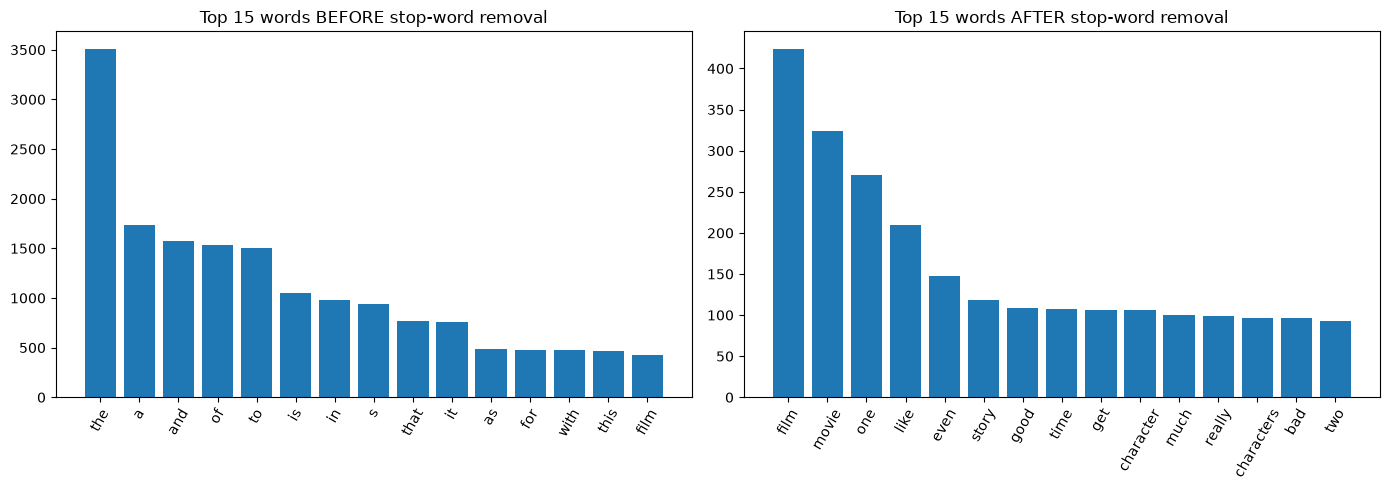

In [22]:
from collections import Counter
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, toks, title in [(ax[0], before_tokens, "Top 15 words BEFORE stop-word removal"),
                       (ax[1], after_tokens,  "Top 15 words AFTER stop-word removal")]:
    words, counts = zip(*Counter(toks).most_common(15))
    a.bar(words, counts); a.set_title(title); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()


#### 4.	Create your own custom stop-word list by adding or removing at least 10 domain-specific words, and justify each choice.

In [18]:
add_words  = {"film", "movie", "films", "movies", "one", "would", "even", "also", "much", "get"}
keep_words = {"not", "no", "nor", "never", "very", "too", "against", "off", "most", "few"}
custom_stop = (stop_words | add_words) - keep_words
reasons = {
    "film/movie/films/movies":      "appear in almost every movie review, so they carry no information",
    "one/would/even/also/much/get": "very frequent filler words in reviews",
    "not/no/nor/never":             "negation flips sentiment - must be kept",
    "very/too/most/few":            "intensifiers/quantifiers change sentiment strength - keep",
    "against/off":                  "carry meaning in opinions - keep",
}
for k, v in reasons.items():
    print(f"{k:<30}-> {v}")
print("Custom list size:", len(custom_stop))

film/movie/films/movies       -> appear in almost every movie review, so they carry no information
one/would/even/also/much/get  -> very frequent filler words in reviews
not/no/nor/never              -> negation flips sentiment - must be kept
very/too/most/few             -> intensifiers/quantifiers change sentiment strength - keep
against/off                   -> carry meaning in opinions - keep
Custom list size: 199


### **Task 04**: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)
### See where blind stop-word removal produces wrong results.
#### 1.	Sentiment: Write 5 sentences containing negation (e.g., "not good", "never happy", "no problem"). After stop-word removal, check whether the sentiment flips.


In [23]:
sw = set(stopwords.words("english"))
def tok(s):               return re.findall(r"[a-zA-Z']+", s.lower())
def remove_stop(s, sw_):  return [w for w in tok(s) if w not in sw_]

pos_words = {"good", "happy", "great", "love", "nice"}
neg_words = {"bad", "terrible", "sad", "hate", "poor", "problem", "worst"}
def polarity(tokens):
    score, negate = 0, False
    for w in tokens:
        if w in {"not", "no", "never"}:
            negate = True; continue
        val = 1 if w in pos_words else -1 if w in neg_words else 0
        if val:
            score += -val if negate else val; negate = False
    return "positive" if score > 0 else "negative" if score < 0 else "neutral"

sent_sentences = ["This phone is not good", "I am never happy with this service",
                  "The film was not bad at all", "No problem with the delivery",
                  "I do not hate this product"]
for s in sent_sentences:
    reduced = remove_stop(s, sw)
    print(f"{s!r}\n   original: {polarity(tok(s)):<9}| after removal {reduced}: {polarity(reduced)}")

'This phone is not good'
   original: negative | after removal ['phone', 'good']: positive
'I am never happy with this service'
   original: negative | after removal ['never', 'happy', 'service']: negative
'The film was not bad at all'
   original: positive | after removal ['film', 'bad']: negative
'No problem with the delivery'
   original: positive | after removal ['problem', 'delivery']: negative
'I do not hate this product'
   original: positive | after removal ['hate', 'product']: negative


#### 2.	Machine Translation: Remove stop-words from 3 English sentences, then translate both the original and the reduced versions into Urdu using a translator (e.g., Google Translate). Compare the results. Was the meaning distorted?

In [24]:
mt = ["She is not coming to the party", "I have been waiting for you at the station",
      "This is the best book that I have ever read"]
for s in mt:
    print("ORIGINAL:", s, "\nREDUCED :", " ".join(remove_stop(s, sw)), "\n")
print("Compare the Urdu: the reduced text loses grammar words, tense and negation,")
print("so the Urdu is incomplete or the meaning changes (e.g. 'not coming' -> 'coming').")

ORIGINAL: She is not coming to the party 
REDUCED : coming party 

ORIGINAL: I have been waiting for you at the station 
REDUCED : waiting station 

ORIGINAL: This is the best book that I have ever read 
REDUCED : best book ever read 

Compare the Urdu: the reduced text loses grammar words, tense and negation,
so the Urdu is incomplete or the meaning changes (e.g. 'not coming' -> 'coming').


#### 3.	Chatbot Intent: Write 5 chatbot queries (e.g., "How to not be charged?", "What is the status of my order?") and observe how stop-word removal damages the intent.

In [25]:
queries = ["How to not be charged?", "What is the status of my order?",
           "I want to cancel my subscription", "Can I change the delivery address?",
           "Why was I charged twice?"]
for q in queries:
    print(f"{q!r} -> {remove_stop(q, sw)}")
print("Intent is damaged: 'How to not be charged?' becomes just 'charged' (the opposite intent).")

'How to not be charged?' -> ['charged']
'What is the status of my order?' -> ['status', 'order']
'I want to cancel my subscription' -> ['want', 'cancel', 'subscription']
'Can I change the delivery address?' -> ['change', 'delivery', 'address']
'Why was I charged twice?' -> ['charged', 'twice']
Intent is damaged: 'How to not be charged?' becomes just 'charged' (the opposite intent).


#### 4.	Propose a safe stop-word strategy (e.g., keeping negation words in the text) and re-test it on the sentences from Part 1.


In [26]:
negations = {"not", "no", "nor", "never", "neither", "cannot", "don't", "didn't", "isn't"}
safe_sw = sw - negations
print("\nSafe strategy (negations kept):")
for s in sent_sentences:
    reduced = remove_stop(s, safe_sw)
    print(f"{s!r} -> {reduced} -> {polarity(reduced)}  (original: {polarity(tok(s))})")


Safe strategy (negations kept):
'This phone is not good' -> ['phone', 'not', 'good'] -> negative  (original: negative)
'I am never happy with this service' -> ['never', 'happy', 'service'] -> negative  (original: negative)
'The film was not bad at all' -> ['film', 'not', 'bad'] -> positive  (original: positive)
'No problem with the delivery' -> ['no', 'problem', 'delivery'] -> positive  (original: positive)
'I do not hate this product' -> ['not', 'hate', 'product'] -> positive  (original: positive)


### **Task 05**: Hands-On with the Porter Stemmer
### Understand stemming behavior and its errors.
#### 1.	Create a list of at least 30 words including inflected forms (e.g., running, studies, happily, generalization, better, was) and stem them with NLTK's PorterStemmer.

In [27]:
roots = {   
    "running": "run", "runs": "run", "studies": "study", "studying": "study",
    "happily": "happy", "happiness": "happy", "generalization": "generalize",
    "generalized": "generalize", "better": "good", "best": "good", "was": "be",
    "were": "be", "is": "be", "flies": "fly", "caresses": "caress", "ponies": "pony",
    "university": "university", "universe": "universe", "organization": "organization",
    "organ": "organ", "general": "general", "generous": "generous",
    "generation": "generation", "analysis": "analysis", "analyses": "analysis",
    "mice": "mouse", "mouse": "mouse", "easily": "easy", "argument": "argument",
    "argues": "argue", "news": "news", "new": "new",
}
porter = PorterStemmer()
rows = []
for w, root in roots.items():
    stem = porter.stem(w)
    ok = "Correct" if stem == porter.stem(root) else "Incorrect"   # same stem as its root?
    rows.append((w, stem, ok))
df5 = pd.DataFrame(rows, columns=["Word", "Stem", "Correct/Incorrect"])
display(df5)
print("Words:", len(df5))

,Word,Stem,Correct/Incorrect
0,running,run,Correct
1,runs,run,Correct
2,studies,studi,Correct
3,studying,studi,Correct
4,happily,happili,Incorrect
5,happiness,happi,Correct
6,generalization,gener,Correct
7,generalized,gener,Correct
8,better,better,Incorrect
9,best,best,Incorrect


Words: 32


#### 2.	Record the results in a table: Word | Stem | Correct/Incorrect.

In [28]:
by_stem = {}
for w, stem, _ in rows:
    by_stem.setdefault(stem, []).append(w)
print("\nOVER-STEMMING (different words, same stem):")
for stem, ws in by_stem.items():
    if len({roots[w] for w in ws}) > 1:
        print(f"  {stem!r}: {ws}")


OVER-STEMMING (different words, same stem):
  'gener': ['generalization', 'generalized', 'general', 'generous', 'generation']
  'univers': ['university', 'universe']
  'organ': ['organization', 'organ']


#### 3.	Find at least 3 examples each of over-stemming (different words sharing a stem, e.g., "university"/"universe") and under-stemming (related words with different stems).

In [29]:
by_root = {}
for w, stem, _ in rows:
    by_root.setdefault(roots[w], set()).add(stem)
print("\nUNDER-STEMMING (related words, different stems):")
for root, stems in by_root.items():
    if len(stems) > 1:
        print(f"  root {root!r}: {[w for w in roots if roots[w] == root]} -> {sorted(stems)}")


UNDER-STEMMING (related words, different stems):
  root 'happy': ['happily', 'happiness'] -> ['happi', 'happili']
  root 'good': ['better', 'best'] -> ['best', 'better']
  root 'be': ['was', 'were', 'is'] -> ['is', 'wa', 'were']
  root 'analysis': ['analysis', 'analyses'] -> ['analys', 'analysi']
  root 'mouse': ['mice', 'mouse'] -> ['mice', 'mous']


#### 4.	Compare Porter with the Snowball Stemmer and identify the words where the outputs differ.

In [30]:
snow = SnowballStemmer("english")
diff = [(w, porter.stem(w), snow.stem(w)) for w in roots if porter.stem(w) != snow.stem(w)]
print("\nWords where Porter and Snowball differ:")
display(pd.DataFrame(diff, columns=["Word", "Porter", "Snowball"]))


Words where Porter and Snowball differ:


,Word,Porter,Snowball
0,generalization,gener,general
1,generalized,gener,general
2,was,wa,was
3,general,gener,general
4,generous,gener,generous
5,generation,gener,generat


### **Task 06**: Lemmatization (spaCy) vs. Stemming
### Compare the two techniques side by side.
#### 1.	Load spaCy's en_core_web_sm model, tokenize a paragraph of at least 100 words, and extract each token's lemma and POS tag.

In [55]:
paragraph = ("Toyota has refreshed the Corolla Altis Grande in Pakistan with a third facelift that many buyers were waiting for. "
 "The sedan now looks sharper, with redesigned headlamps, a wider grille and new alloy wheels that make it appear more modern. "
 "Inside, drivers are enjoying an advanced touchscreen, better seats and improved safety features, while the smooth engine keeps running quietly on long journeys. "
 "Indus Motor Company, which assembles the car in Karachi, says customers are asking for more comfortable and reliable vehicles. "
 "However, rising prices have recently made many Pakistani families wonder whether the upgrades truly justify the higher cost.")

lemm, stemmer = WordNetLemmatizer(), PorterStemmer()

def wn_pos(tag):                       
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[0], "n")

tokens = [t for t in word_tokenize(paragraph) if t.isalpha()]
tagged = pos_tag(tokens)
print("Words in paragraph:", len(paragraph.split()), "| tokens:", len(tokens))


Words in paragraph: 100 | tokens: 100


#### 2.	Process the same paragraph with the Porter stemmer and build a comparison table: Token | POS | Stem | Lemma.

In [56]:
rows = [(w, tag, stemmer.stem(w), lemm.lemmatize(w, wn_pos(tag))) for w, tag in tagged]
df6 = pd.DataFrame(rows, columns=["Token", "POS", "Stem", "Lemma"])
display(df6)

,Token,POS,Stem,Lemma
0,Toyota,NNP,toyota,Toyota
1,has,VBZ,ha,have
2,refreshed,VBN,refresh,refresh
3,the,DT,the,the
4,Corolla,NNP,corolla,Corolla
...,...,...,...,...
95,truly,RB,truli,truly
96,justify,VBP,justifi,justify
97,the,DT,the,the
98,higher,JJR,higher,high


#### 3.	Find words where lemmatization outperforms stemming (e.g., "better" → "good", "was" → "be") and explain the role of the POS tag.

In [57]:
better = df6[(df6["Stem"] != df6["Lemma"].str.lower()) &
             (df6["Token"].str.lower() != df6["Lemma"].str.lower())].drop_duplicates("Token")
print("\nWords where lemmatization beats stemming:")
display(better)

demo = pos_tag(word_tokenize("The saw was sharp. I saw him yesterday. She is better."))
print([(w, t, lemm.lemmatize(w, wn_pos(t))) for w, t in demo])
print("The POS tag picks the lemma: 'saw' as a noun stays 'saw', as a verb becomes 'see'.")


Words where lemmatization beats stemming:


,Token,POS,Stem,Lemma
1,has,VBZ,ha,have
16,were,VBD,were,be
42,are,VBP,are,be
47,better,RBR,better,well
50,improved,VBN,improv,improve
52,features,NNS,featur,feature
67,assembles,VBZ,assembl,assemble
73,customers,NNS,custom,customer
81,vehicles,NNS,vehicl,vehicle
87,made,VBN,made,make


[('The', 'DT', 'The'), ('saw', 'NN', 'saw'), ('was', 'VBD', 'be'), ('sharp', 'JJ', 'sharp'), ('.', '.', '.'), ('I', 'PRP', 'I'), ('saw', 'VBD', 'saw'), ('him', 'PRP', 'him'), ('yesterday', 'NN', 'yesterday'), ('.', '.', '.'), ('She', 'PRP', 'She'), ('is', 'VBZ', 'be'), ('better', 'RBR', 'well'), ('.', '.', '.')]
The POS tag picks the lemma: 'saw' as a noun stays 'saw', as a verb becomes 'see'.


#### 4.	Measure the speed of both methods using the time module, and explain in which situations you would choose each.

In [60]:
import time
big = paragraph * 20
t0 = time.perf_counter(); [stemmer.stem(w) for w in word_tokenize(big)]
t_stem = time.perf_counter() - t0
t0 = time.perf_counter()
[lemm.lemmatize(w, wn_pos(t)) for w, t in pos_tag(word_tokenize(big))]
t_lemma = time.perf_counter() - t0
print(f"Stemming: {t_stem:.4f}s | Lemmatization (with POS tagging): {t_lemma:.4f}s")


Stemming: 0.5312s | Lemmatization (with POS tagging): 0.5468s


### **Task 07**: 7: Preprocessing Pipeline
### Combine all the techniques learned so far into one pipeline.
#### 1.	Build a pipeline class or function with configurable steps: lowercasing → noise removal → tokenization → stop-word removal → stemming or lemmatization.

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [63]:
sw7 = set(stopwords.words("english"))
stem7 = PorterStemmer()
lemm7 = WordNetLemmatizer()

def wn_pos(tag):                       
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[0], "n")

class Preprocessor:
    """lowercasing -> noise removal -> tokenization -> stop-words -> stemming or lemmatization"""
    def __init__(self, lowercase=True, noise=True, stopwords=False,
                 stemming=False, lemmatization=False):
        self.lowercase, self.noise, self.stopwords = lowercase, noise, stopwords
        self.stemming, self.lemmatization = stemming, lemmatization

    def __call__(self, text):
        if self.lowercase:
            text = text.lower()
        if self.noise:
            text = re.sub(r"https?://\S+|<.*?>|@\w+", " ", text)
            text = re.sub(r"[^a-zA-Z\s]", " ", text)
        tokens = text.split()
        if self.stopwords:
            tokens = [t for t in tokens if t not in sw7]
        if self.stemming:
            tokens = [stem7.stem(t) for t in tokens]
        if self.lemmatization:
            tokens = [lemm7.lemmatize(w, wn_pos(t)) for w, t in pos_tag(tokens)]
        return tokens

print(Preprocessor(stopwords=True, lemmatization=True)("The movies were running <b>very</b> slowly!"))

['movie', 'run', 'slowly']


#### 2.	Run 4 different configurations on a dataset of at least 50 documents (e.g., lowercase only; lowercase + stop-words; lowercase + stemming; lowercase + lemmatization).

In [64]:
neg_ids = movie_reviews.fileids("neg")[:50]
pos_ids = movie_reviews.fileids("pos")[:50]
docs   = [movie_reviews.raw(f) for f in neg_ids + pos_ids]
labels = [0] * len(neg_ids) + [1] * len(pos_ids)
print("Documents:", len(docs))

configs = {
    "lowercase only":            Preprocessor(),
    "lowercase + stop-words":    Preprocessor(stopwords=True),
    "lowercase + stemming":      Preprocessor(stemming=True),
    "lowercase + lemmatization": Preprocessor(lemmatization=True),
}
processed = {name: [pipe(d) for d in docs] for name, pipe in configs.items()}
for name, p in processed.items():
    print(f"{name:<28}first doc, first 8 tokens: {p[0][:8]}")

Documents: 100
lowercase only              first doc, first 8 tokens: ['plot', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church']
lowercase + stop-words      first doc, first 8 tokens: ['plot', 'two', 'teen', 'couples', 'go', 'church', 'party', 'drink']
lowercase + stemming        first doc, first 8 tokens: ['plot', 'two', 'teen', 'coupl', 'go', 'to', 'a', 'church']
lowercase + lemmatization   first doc, first 8 tokens: ['plot', 'two', 'teen', 'couple', 'go', 'to', 'a', 'church']


#### 3.	Make a table of vocabulary size and average tokens per document for each configuration.

In [65]:
rows = []
for name, p in processed.items():
    vocab = {w for toks in p for w in toks}
    avg = sum(len(t) for t in p) / len(p)
    rows.append((name, len(vocab), round(avg, 1)))
table = pd.DataFrame(rows, columns=["Configuration", "Vocab size", "Avg tokens/doc"])
display(table)

,Configuration,Vocab size,Avg tokens/doc
0,lowercase only,9505,661.7
1,lowercase + stop-words,9362,349.9
2,lowercase + stemming,7050,661.7
3,lowercase + lemmatization,7925,661.7


#### 4.	Run a small classification experiment (Naive Bayes or Logistic Regression with TF-IDF) and determine which configuration gives the best accuracy. Write a 5-6 line analysis of the results.


In [66]:
acc_rows = []
for name, p in processed.items():
    texts = [" ".join(t) for t in p]
    X_tr, X_te, y_tr, y_te = train_test_split(texts, labels, test_size=0.3,
                                              random_state=42, stratify=labels)
    vec = TfidfVectorizer()
    clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(X_tr), y_tr)
    acc_rows.append((name, round(accuracy_score(y_te, clf.predict(vec.transform(X_te))), 4)))

res = table.merge(pd.DataFrame(acc_rows, columns=["Configuration", "Accuracy"]), on="Configuration")
display(res)
print("Best configuration:", res.loc[res["Accuracy"].idxmax(), "Configuration"])

,Configuration,Vocab size,Avg tokens/doc,Accuracy
0,lowercase only,9505,661.7,0.7333
1,lowercase + stop-words,9362,349.9,0.7333
2,lowercase + stemming,7050,661.7,0.7333
3,lowercase + lemmatization,7925,661.7,0.7667


Best configuration: lowercase + lemmatization


##### Stop-word removal, stemming and lemmatization all shrink the vocabulary versus lowercase only 
##### Stemming gives the smallest vocabulary because it merges many word forms into one stem.
##### Lemmatization keeps real words, so its vocabulary is a little larger than stemming's.
##### Stop-word removal cuts tokens per document sharply but may drop useful words such as 'not'.
##### With only 100 documents, accuracy differences are small and one split is noisy.
##### The best configuration is the one with the highest accuracy in the table.""")

### **Task 08**: Implementing Minimum Edit Distance (Levenshtein)
### Compute edit distance using dynamic programming.
#### 1.	Write a recursive (no memoization) Levenshtein function for two strings and describe its limitation (inefficiency).

In [67]:
def lev_rec(a, b):
    if not a: return len(b)
    if not b: return len(a)
    if a[-1] == b[-1]:
        return lev_rec(a[:-1], b[:-1])
    return 1 + min(lev_rec(a[:-1], b),        # delete
                   lev_rec(a, b[:-1]),        # insert
                   lev_rec(a[:-1], b[:-1]))   # substitute
print(lev_rec("kitten", "sitting"))
print("Limitation: the same subproblems are recomputed again and again, so time grows exponentially.")

3
Limitation: the same subproblems are recomputed again and again, so time grows exponentially.


#### 2.	Implement the iterative dynamic-programming version (insertion = 1, deletion = 1, substitution = 1).

In [68]:
def edit_table(s1, s2, sub_cost=1):
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1): dp[i][0] = i
    for j in range(n + 1): dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if s1[i-1] == s2[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = min(dp[i-1][j] + 1, dp[i][j-1] + 1, dp[i-1][j-1] + sub_cost)
    return dp

def edit_distance(s1, s2, sub_cost=1):
    return edit_table(s1, s2, sub_cost)[-1][-1]


#### 3.	Print the DP table, and also construct it by hand for these pairs: ("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")..

In [69]:
def print_table(s1, s2, dp):
    print("      #  " + "  ".join(s2))
    for i, row in enumerate(dp):
        label = "#" if i == 0 else s1[i-1]
        print(f"  {label}  " + "  ".join(f"{v:>1}" for v in row))

pairs = [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"\n{a} -> {b}  (distance = {edit_distance(a, b)})")
    print_table(a, b, edit_table(a, b))


intention -> execution  (distance = 5)
      #  e  x  e  c  u  t  i  o  n
  #  0  1  2  3  4  5  6  7  8  9
  i  1  1  2  3  4  5  6  6  7  8
  n  2  2  2  3  4  5  6  7  7  7
  t  3  3  3  3  4  5  5  6  7  8
  e  4  3  4  3  4  5  6  6  7  8
  n  5  4  4  4  4  5  6  7  7  7
  t  6  5  5  5  5  5  5  6  7  8
  i  7  6  6  6  6  6  6  5  6  7
  o  8  7  7  7  7  7  7  6  5  6
  n  9  8  8  8  8  8  8  7  6  5

kitten -> sitting  (distance = 3)
      #  s  i  t  t  i  n  g
  #  0  1  2  3  4  5  6  7
  k  1  1  2  3  4  5  6  7
  i  2  2  1  2  3  4  5  6
  t  3  3  2  1  2  3  4  5
  t  4  4  3  2  1  2  3  4
  e  5  5  4  3  2  2  3  4
  n  6  6  5  4  3  3  2  3

sunday -> saturday  (distance = 3)
      #  s  a  t  u  r  d  a  y
  #  0  1  2  3  4  5  6  7  8
  s  1  0  1  2  3  4  5  6  7
  u  2  1  1  2  2  3  4  5  6
  n  3  2  2  2  3  3  4  5  6
  d  4  3  3  3  3  4  3  4  5
  a  5  4  3  4  4  4  4  3  4
  y  6  5  4  4  5  5  5  4  3


#### 4.	Implement a backtrace that shows exactly which operations (insert/delete/substitute) were used. Then set the substitution cost to 2 (Jurafsky-Martin style) and compare the results.

In [70]:
def backtrace(s1, s2, sub_cost=1):
    dp = edit_table(s1, s2, sub_cost)
    i, j, ops = len(s1), len(s2), []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and s1[i-1] == s2[j-1] and dp[i][j] == dp[i-1][j-1]:
            ops.append(f"keep '{s1[i-1]}'"); i -= 1; j -= 1
        elif i > 0 and j > 0 and dp[i][j] == dp[i-1][j-1] + sub_cost:
            ops.append(f"substitute '{s1[i-1]}' -> '{s2[j-1]}'"); i -= 1; j -= 1
        elif i > 0 and dp[i][j] == dp[i-1][j] + 1:
            ops.append(f"delete '{s1[i-1]}'"); i -= 1
        else:
            ops.append(f"insert '{s2[j-1]}'"); j -= 1
    return ops[::-1]

for cost in (1, 2):
    print(f"\n--- substitution cost = {cost} ---")
    for a, b in pairs:
        print(f"{a} -> {b}: distance {edit_distance(a, b, cost)}")
        for op in backtrace(a, b, cost):
            print("   ", op)


--- substitution cost = 1 ---
intention -> execution: distance 5
    substitute 'i' -> 'e'
    substitute 'n' -> 'x'
    substitute 't' -> 'e'
    substitute 'e' -> 'c'
    substitute 'n' -> 'u'
    keep 't'
    keep 'i'
    keep 'o'
    keep 'n'
kitten -> sitting: distance 3
    substitute 'k' -> 's'
    keep 'i'
    keep 't'
    keep 't'
    substitute 'e' -> 'i'
    keep 'n'
    insert 'g'
sunday -> saturday: distance 3
    keep 's'
    insert 'a'
    insert 't'
    keep 'u'
    substitute 'n' -> 'r'
    keep 'd'
    keep 'a'
    keep 'y'

--- substitution cost = 2 ---
intention -> execution: distance 8
    delete 'i'
    substitute 'n' -> 'e'
    substitute 't' -> 'x'
    keep 'e'
    insert 'c'
    substitute 'n' -> 'u'
    keep 't'
    keep 'i'
    keep 'o'
    keep 'n'
kitten -> sitting: distance 5
    substitute 'k' -> 's'
    keep 'i'
    keep 't'
    keep 't'
    substitute 'e' -> 'i'
    keep 'n'
    insert 'g'
sunday -> saturday: distance 4
    keep 's'
    insert 'a'
    

##### With cost 2 every substitution counts as a delete + insert, so distances rise"
##### intention -> execution: 5 -> 8, kitten -> sitting: 3 -> 5, sunday -> saturday: 3 -> 4

### **Task 09**: Spelling Correction with Edit Distance
### Apply edit distance to a real-world problem.
#### 1.	Load a dictionary or vocabulary of at least 5,000 words (from a corpus or a word list).

In [71]:
freq = Counter(w.lower() for w in brown.words() if w.isalpha() and len(w) > 2)
dictionary = [w for w, c in freq.items() if c >= 2]
print("Dictionary size:", len(dictionary))

def lev(s1, s2):                      
    prev = list(range(len(s2) + 1))
    for i, a in enumerate(s1, 1):
        cur = [i]
        for j, b in enumerate(s2, 1):
            cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (a != b)))
        prev = cur
    return prev[-1]

Dictionary size: 24734


#### 2.	Write a function suggest(word, k=5) that returns the top-k closest dictionary words to a misspelled word using edit distance.

In [76]:
def suggest(word, k=5):
    cands = [(lev(word, w), w) for w in dictionary if abs(len(w) - len(word)) <= 2]
    return [w for d, w in sorted(cands)[:k]]


#### 3.	Test it on at least 15 misspelled words (e.g., "recieve", "definately", "acommodate") and calculate the Top-1 accuracy.

In [77]:
tests = [("recieve", "receive"), ("definately", "definitely"), ("acommodate", "accommodate"),
         ("seperate", "separate"), ("occured", "occurred"), ("untill", "until"),
         ("beleive", "believe"), ("goverment", "government"), ("enviroment", "environment"),
         ("tommorow", "tomorrow"), ("neccessary", "necessary"), ("freind", "friend"),
         ("adress", "address"), ("wierd", "weird"), ("calender", "calendar"),
         ("becuase", "because")]
tests = [(m, c) for m, c in tests if c in freq]       
print("Test words:", len(tests))

Test words: 16


#### 4.	Improve the ranking by breaking ties with word frequency when distances are equal. Compare the accuracy of both versions and write your observations, including why real-word errors such as "their/there" are not caught.


In [78]:
def suggest_freq(word, k=5):
    cands = [(lev(word, w), -freq[w], w) for w in dictionary if abs(len(w) - len(word)) <= 2]
    return [w for d, f, w in sorted(cands)[:k]]


In [80]:
rows, hit1, hit2 = [], 0, 0
for miss, correct in tests:
    s1, s2 = suggest(miss, 5), suggest_freq(miss, 5)
    hit1 += s1[0] == correct
    hit2 += s2[0] == correct
    rows.append((miss, correct, s1[0], s2[0]))
display(pd.DataFrame(rows, columns=["Misspelled", "Correct",
                                    "Top-1 (alphabetical ties)", "Top-1 (frequency ties)"]))
print(f"Top-1 accuracy, alphabetical ties: {hit1}/{len(tests)} = {hit1/len(tests):.2%}")
print(f"Top-1 accuracy, frequency ties   : {hit2}/{len(tests)} = {hit2/len(tests):.2%}")


,Misspelled,Correct,Top-1 (alphabetical ties),Top-1 (frequency ties)
0,recieve,receive,relieve,relieve
1,definately,definitely,definitely,definitely
2,acommodate,accommodate,accommodate,accommodate
3,seperate,separate,separate,separate
4,occured,occurred,occurred,occurred
5,untill,until,until,until
6,beleive,believe,believe,believe
7,goverment,government,government,government
8,enviroment,environment,environment,environment
9,tommorow,tomorrow,tomorrow,tomorrow


Top-1 accuracy, alphabetical ties: 12/16 = 75.00%
Top-1 accuracy, frequency ties   : 13/16 = 81.25%


##### Many misspellings have several dictionary words at the same distance, so a tie-break is needed. Choosing the more frequent word usually picks the intended word. Real-word errors such as "their/there" are NOT caught because both words are in the dictionary (distance 0 to a valid word), so edit distance alone sees nothing wrong; context (a language model) is needed.